# Monte-Carlo trajectories

The trajectory engine follows one statevector per trajectory and picks a Kraus branch at random for each noise channel.
Averaged over trajectories it reproduces the density matrix, at 2ⁿ memory instead of 4ⁿ. By default it runs one trajectory
per shot, up to `QPUTWIN_MAX_TRAJECTORIES` (2000 by default) per job, which makes the sampled counts exact; beyond that, shots
are drawn from each trajectory's final distribution.

In [1]:
from qputwin_demo import *

connect()

QPUTwin at http://localhost:8000: ready, 7 twins reachable


{'status': 'ready',
 'instance': 'c88add07efb8:7:a77a42',
 'job_store': 'ok',
 'backends_reachable': ['quantinuum_helios',
  'ionq_forte',
  'rigetti_ankaa_3',
  'iqm_emerald',
  'ibm_heron',
  'ibm_nighthawk',
  'google_willow']}

## 1. Convergence with the number of trajectories

Noisy GHZ₄ on Emerald with a fixed 20 000 shots and a growing number of trajectories (up to the server's limit of 2000), against the exact density matrix.

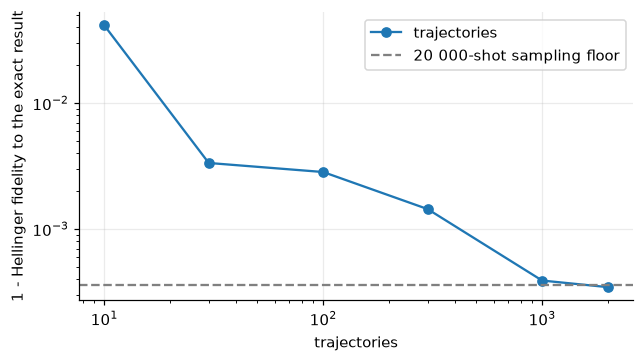

In [2]:
prog = ghz(4)
reference = run("iqm_emerald", prog, shots=200000, noise=True, engine="density_matrix")["result"]["counts"]
Ts = [10, 30, 100, 300, 1000, 2000]
dist = []
for T in Ts:                                 # mean over three seeds per point
    dist.append(np.mean([1 - hellinger(reference, run("iqm_emerald", prog, shots=20000, engine="trajectory", seed=s,
                                                      noise={"model": "device", "trajectories": T})["result"]["counts"])
                         for s in (1, 2, 3)]))
floor = 1 - hellinger(reference, run("iqm_emerald", prog, shots=20000, noise=True, engine="density_matrix", seed=99)["result"]["counts"])
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.loglog(Ts, dist, "o-", label="trajectories")
ax.axhline(floor, ls="--", color="grey", label="20 000-shot sampling floor")
ax.set_xlabel("trajectories"); ax.set_ylabel("1 - Hellinger fidelity to the exact result"); ax.legend(); plt.show()

## 2. One trajectory per shot is exact sampling

With 2000 shots the default runs one trajectory per shot, so the counts are an exact sample of the noisy distribution: averaged over seeds, their distance from a density-matrix sample is the same as between two density-matrix samples.

In [3]:
prog = ghz(5)
dm_dm, dm_tr = [], []
for seed in range(1, 9):
    a = run("iqm_emerald", prog, shots=2000, noise=True, engine="density_matrix", seed=seed)["result"]["counts"]
    b = run("iqm_emerald", prog, shots=2000, noise=True, engine="density_matrix", seed=100 + seed)["result"]["counts"]
    t = run("iqm_emerald", prog, shots=2000, noise=True, engine="trajectory", seed=200 + seed)
    dm_dm.append(1 - hellinger(a, b)); dm_tr.append(1 - hellinger(a, t["result"]["counts"]))
print("trajectories used per job:", t["result"]["noise"]["options"].get("trajectories") or "one per shot")
print(f"mean 1 - Hellinger, density matrix vs density matrix: {np.mean(dm_dm):.4f}")
print(f"mean 1 - Hellinger, density matrix vs trajectories:   {np.mean(dm_tr):.4f}")

trajectories used per job: one per shot
mean 1 - Hellinger, density matrix vs density matrix: 0.0101
mean 1 - Hellinger, density matrix vs trajectories:   0.0094


## 3. Wide noisy circuits

A 16-qubit noisy GHZ is too wide for a density matrix in a worker's memory; `auto` runs it on trajectories on every twin.

In [4]:
rows = []
for b in ALL_BACKENDS:
    r = run(b, ghz(16), shots=2000, noise=True, routing=True)
    w = r["telemetry"]["workload"]
    rows.append({"twin": NAMES[b], "engine": w["engine"], "simulated qubits": w["simulated_qubits"],
                 "GHZ16 success": round(success(r, ["0" * 16, "1" * 16]), 4),
                 "engine ms": round(r["telemetry"]["breakdown"]["simulation_ms"], 1)})
pd.DataFrame(rows).set_index("twin")

,engine,simulated qubits,GHZ16 success,engine ms
twin,,,,
Helios,trajectory,16,0.9780,2608.0
Forte,trajectory,16,0.8690,5199.2
Ankaa-3,trajectory,16,0.3310,5859.5
Emerald,trajectory,16,0.3780,6259.7
Heron r3,trajectory,16,0.8965,2996.0
Nighthawk,trajectory,16,0.7560,3254.1
Willow,trajectory,16,0.7590,3842.6


## 4. Batched trajectories and the sequential walk

Branch-free circuits run many trajectories together in one fused state. Mid-circuit measurement, reset and feed-forward branch each shot, so they keep the sequential walk. The noise report says which one ran.

In [5]:
branch_free = ghz(8)
with_reset = program(8, ["h q[0]", *(f"cx q[{i}],q[{i + 1}]" for i in range(7)), "reset q[7]", "x q[7]"])
for name, prog in (("GHZ8", branch_free), ("GHZ8 with a reset", with_reset)):
    r = run("iqm_emerald", prog, shots=2000, noise=True, engine="trajectory")
    n = r["result"]["noise"]
    walk = f"batched, {n['batch_rows']} trajectories per state" if n.get("batched") else "sequential walk"
    print(f"{name:18s} {walk:36s} engine ms: {r['telemetry']['breakdown']['simulation_ms']:.1f}")

GHZ8               batched, 128 trajectories per state  engine ms: 375.6


GHZ8 with a reset  sequential walk                      engine ms: 2807.4


## Takeaways

- Trajectories converge to the density matrix as 1/√T and are exact with one trajectory per shot.
- They make noisy circuits possible far beyond the width of a density matrix.